# 04 · Geç Teslimat Tahmin Modeli

01 ve 03 numaralı notebook'lar, geç teslimatın müşteri memnuniyetini en çok bozan etken olduğunu gösterdi.
Bu notebook'ta, **sipariş verildiği anda** o siparişin tahmini teslim tarihinden sonra ulaşıp ulaşmayacağını tahmin eden bir model kuruluyor.

**İş kullanımı:** Riskli siparişleri baştan işaretleyip lojistik önceliği vermek veya müşteriyi önceden bilgilendirmek.

**Yöntem ilkeleri**
- **Sızıntı yok:** Yalnızca sipariş anında (veya ödeme onayından hemen sonra) bilinen bilgiler kullanıldı. Kargoya verilme tarihi gibi sonradan oluşan alanlar modele girmedi.
- **Zamana göre doğrulama:** Model Mart 2018 ve öncesindeki siparişlerle eğitildi, **Nisan–Ağustos 2018** siparişleriyle test edildi. Gerçek hayatta model geçmişle eğitilip gelecekte kullanılacağı için bu, rastgele bölmeden daha dürüst bir ölçüm.
- **Dengesiz sınıf:** Siparişlerin yalnızca ~%7'si geç. Bu yüzden doğruluk (accuracy) yerine ROC-AUC, PR-AUC ve "riskli ilk %10'da yakalanan geç sipariş oranı" kullanıldı.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, QuantileTransformer, TargetEncoder

import ortak
from ortak import MAVI, ORTA_GRI, SOLUK, TURUNCU, YAZI, YUZDE, kaydet, sayi

ortak.stil_uygula()
t = ortak.tablolari_yukle()
df = ortak.siparis_tablosu(t)
koord = ortak.koordinatlar()
df["mesafe_km"] = df["order_id"].map(ortak.siparis_mesafesi(t, df, koord))

## 1. Özellik mühendisliği

In [2]:
k = (t["kalemler"].merge(t["urunler"], on="product_id", how="left")
     .merge(t["saticilar"][["seller_id", "seller_state"]], on="seller_id", how="left"))
k["hacim_cm3"] = k["product_length_cm"] * k["product_height_cm"] * k["product_width_cm"]

# Siparişin "ana" ürünü: en pahalı kalem (satıcı, satıcı eyaleti ve kategori buradan alınır)
ana = (k.sort_values("price", ascending=False).drop_duplicates("order_id")
       .set_index("order_id")[["seller_id", "seller_state", "kategori"]])
kalem = k.groupby("order_id").agg(
    satici_sayisi=("seller_id", "nunique"), toplam_agirlik_g=("product_weight_g", "sum"),
    toplam_hacim_cm3=("hacim_cm3", "sum"), kargo_limit=("shipping_limit_date", "max"))
ana_odeme = (t["odemeler"].sort_values("payment_value").drop_duplicates("order_id", keep="last")
             .set_index("order_id")[["payment_type", "payment_installments"]])

# Platform yükü: sipariş gününden önceki 7 günde verilen toplam sipariş (sipariş anında bilinir)
gunluk = t["siparisler"].set_index("order_purchase_timestamp").resample("D").size()
yuk = gunluk.rolling(7, min_periods=1).sum().shift(1)

v = df.set_index("order_id").join(ana).join(kalem).join(ana_odeme)
alim = v["order_purchase_timestamp"]
X = pd.DataFrame({
    "tahmini_sure_gun": (v["order_estimated_delivery_date"] - alim).dt.total_seconds() / 86400,
    "onay_suresi_saat": (v["order_approved_at"] - alim).dt.total_seconds() / 3600,
    "kargo_limit_gun": (v["kargo_limit"] - alim).dt.total_seconds() / 86400,
    "mesafe_km": v["mesafe_km"],
    "ayni_eyalet": (v["seller_state"] == v["customer_state"]).astype(int),
    "musteri_eyalet": v["customer_state"],
    "satici_eyalet": v["seller_state"],
    "kategori": v["kategori"],
    "satici": v["seller_id"],
    "urun_adedi": v["urun_adedi"],
    "satici_sayisi": v["satici_sayisi"],
    "urun_tutari": v["urun_tutari"],
    "kargo_ucreti": v["kargo_ucreti"],
    "kargo_orani": v["kargo_ucreti"] / v["urun_tutari"],
    "toplam_agirlik_g": v["toplam_agirlik_g"],
    "toplam_hacim_cm3": v["toplam_hacim_cm3"],
    "odeme_turu": v["payment_type"].fillna("bilinmiyor"),
    "taksit": v["payment_installments"],
    "haftanin_gunu": alim.dt.dayofweek,
    "son7gun_siparis": alim.dt.normalize().map(yuk),
})
y = v["gec"].astype(int)

AD = {
    "tahmini_sure_gun": "Tahmini teslim süresi (gün)", "onay_suresi_saat": "Ödeme onay süresi (saat)",
    "kargo_limit_gun": "Kargoya verme süresi (gün)", "mesafe_km": "Satıcı–müşteri mesafesi (km)",
    "ayni_eyalet": "Aynı eyalet mi?", "musteri_eyalet": "Müşteri eyaleti", "satici_eyalet": "Satıcı eyaleti",
    "kategori": "Ürün kategorisi", "satici": "Satıcının geçmiş gecikme oranı", "urun_adedi": "Ürün adedi",
    "satici_sayisi": "Satıcı sayısı", "urun_tutari": "Ürün tutarı (R$)", "kargo_ucreti": "Kargo ücreti (R$)",
    "kargo_orani": "Kargo / ürün tutarı", "toplam_agirlik_g": "Toplam ağırlık (g)",
    "toplam_hacim_cm3": "Toplam hacim (cm³)", "odeme_turu": "Ödeme türü", "taksit": "Taksit sayısı",
    "haftanin_gunu": "Haftanın günü", "son7gun_siparis": "Platform yükü (önceki 7 günün siparişi)",
}
print(f"{X.shape[0]:,} sipariş, {X.shape[1]} özellik".replace(",", "."))
pd.DataFrame({"açıklama": AD, "eksik (%)": (X.isna().mean() * 100).round(2)})

96.203 sipariş. 20 özellik


,açıklama,eksik (%)
tahmini_sure_gun,Tahmini teslim süresi (gün),0.00
onay_suresi_saat,Ödeme onay süresi (saat),0.01
kargo_limit_gun,Kargoya verme süresi (gün),0.00
mesafe_km,Satıcı–müşteri mesafesi (km),0.50
ayni_eyalet,Aynı eyalet mi?,0.00
musteri_eyalet,Müşteri eyaleti,0.00
satici_eyalet,Satıcı eyaleti,0.00
kategori,Ürün kategorisi,0.00
satici,Satıcının geçmiş gecikme oranı,0.00
urun_adedi,Ürün adedi,0.00


## 2. Zamana göre eğitim / test ayrımı

In [3]:
KESIM = pd.Timestamp("2018-04-01")
egitim = (alim < KESIM).to_numpy()
X_egitim, X_test, y_egitim, y_test = X[egitim], X[~egitim], y[egitim], y[~egitim]
pd.DataFrame({
    "dönem": ["Oca 2017 – Mar 2018", "Nis 2018 – Ağu 2018"],
    "sipariş": [len(y_egitim), len(y_test)],
    "geç oranı (%)": [y_egitim.mean() * 100, y_test.mean() * 100],
}, index=["eğitim", "test"]).round(2)

,dönem,sipariş,geç oranı (%)
eğitim,Oca 2017 – Mar 2018,64053,7.98
test,Nis 2018 – Ağu 2018,32150,4.42


Test döneminde geç teslimat oranı eğitim dönemine göre daha düşük; özellikle Şubat–Mart 2018'deki gecikme dalgası eğitim verisinde kalıyor.
Model, farklı koşullara sahip bir gelecek döneme genelleşmek zorunda. Bu, gerçekçi ama zorlu bir test.

## 3. Modeller

| Model | Açıklama |
|---|---|
| **Lojistik regresyon** | Temel (baseline) model. Sayısal özellikler normal dağılıma dönüştürüldü, eyaletler one-hot kodlandı. |
| **Gradient boosting** | `HistGradientBoostingClassifier`. Eyaletleri doğrudan kategorik değişken olarak kullanır, doğrusal olmayan ilişkileri yakalar. |

Yüzlerce satıcı ve kategori için **hedef kodlama** (target encoding) kullanıldı: her satıcı, eğitim verisindeki gecikme oranıyla temsil ediliyor.
Kodlama çapraz doğrulamayla (5 katman) yapıldığı için bir siparişin kendi etiketi kendi özelliğine sızmıyor.

In [4]:
hedef_kod = ["satici", "kategori"]
kategorik = ["musteri_eyalet", "satici_eyalet", "odeme_turu"]
sayisal = [c for c in X.columns if c not in hedef_kod + kategorik]

lojistik = Pipeline([
    ("on_isleme", ColumnTransformer([
        ("hedef", TargetEncoder(target_type="binary", random_state=42), hedef_kod),
        ("kat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), kategorik),
        ("sayi", make_pipeline(SimpleImputer(strategy="median"),
                               QuantileTransformer(output_distribution="normal", random_state=42)), sayisal),
    ])),
    ("model", LogisticRegression(max_iter=3000, class_weight="balanced")),
])

boosting = Pipeline([
    ("on_isleme", ColumnTransformer([
        ("hedef", TargetEncoder(target_type="binary", random_state=42), hedef_kod),
        ("kat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), kategorik),
    ], remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")),
    ("model", HistGradientBoostingClassifier(
        categorical_features=kategorik, learning_rate=0.05, max_iter=500, max_leaf_nodes=31,
        l2_regularization=1.0, early_stopping=True, validation_fraction=0.15, n_iter_no_change=30,
        random_state=42)),
])


def yakalama(y_gercek, olasilik, oran):
    """En riskli `oran` kadar siparişte, tüm geç siparişlerin ne kadarı yakalanıyor?"""
    sira = np.argsort(-olasilik)
    n = int(len(olasilik) * oran)
    return np.asarray(y_gercek)[sira[:n]].sum() / np.asarray(y_gercek).sum()


modeller = {"Lojistik regresyon": lojistik, "Gradient boosting": boosting}
tahmin, sonuc = {}, {}
for ad, model in modeller.items():
    model.fit(X_egitim, y_egitim)
    tahmin[ad] = model.predict_proba(X_test)[:, 1]
    sonuc[ad] = {"ROC-AUC": roc_auc_score(y_test, tahmin[ad]),
                 "PR-AUC": average_precision_score(y_test, tahmin[ad]),
                 "ilk %10'da yakalanan geç sipariş (%)": yakalama(y_test, tahmin[ad], 0.10) * 100}
sonuc["Rastgele tahmin"] = {"ROC-AUC": 0.5, "PR-AUC": y_test.mean(), "ilk %10'da yakalanan geç sipariş (%)": 10.0}
pd.DataFrame(sonuc).T.round(3)

,ROC-AUC,PR-AUC,ilk %10'da yakalanan geç sipariş (%)
Lojistik regresyon,0.75,0.11,31.53
Gradient boosting,0.68,0.09,23.36
Rastgele tahmin,0.50,0.04,10.00


## 4. Dönemlere göre performans: model ne zaman bozuluyor?

Tek bir test skoru, performansın dönem içinde nasıl değiştiğini gizleyebilir.
Aşağıda her iki model için ROC-AUC **her test ayında ayrı ayrı** hesaplandı.
Aynı ay içindeki siparişler benzer koşullarda teslim edildiği için bu ölçüm, modelin siparişleri birbirine göre ne kadar iyi sıraladığını gösterir.

C:\Users\fazfu\AppData\Local\Temp\ipykernel_27548\1100748853.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby("ay").apply(lambda g: roc_auc_score(g["y"], g["p"]))
C:\Users\fazfu\AppData\Local\Temp\ipykernel_27548\1100748853.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby("ay").apply(lambda g: roc_auc_score(g["y"], g["p"]))


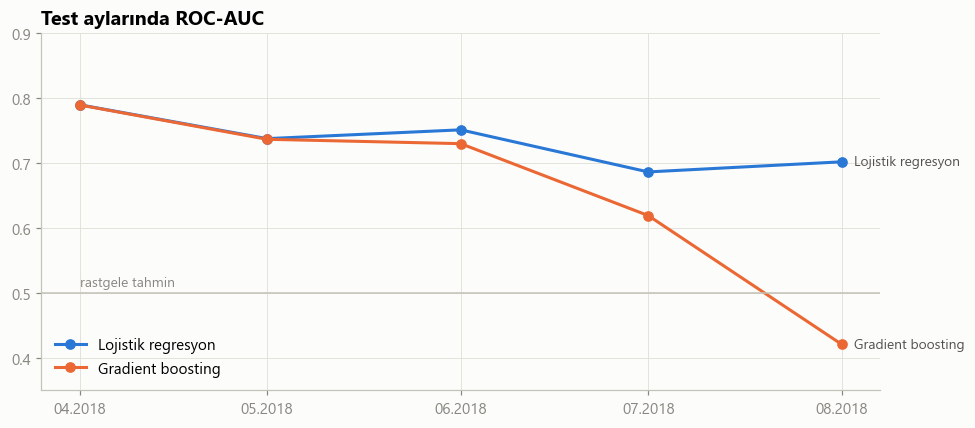

,Lojistik regresyon,Gradient boosting
ay,,
2018-04-01,0.79,0.79
2018-05-01,0.74,0.74
2018-06-01,0.75,0.73
2018-07-01,0.69,0.62
2018-08-01,0.70,0.42


In [5]:
test_ay = alim[~egitim].dt.to_period("M").dt.to_timestamp().to_numpy()
aylik_auc = pd.DataFrame({
    ad: pd.DataFrame({"y": y_test.to_numpy(), "p": p, "ay": test_ay})
          .groupby("ay").apply(lambda g: roc_auc_score(g["y"], g["p"]))
    for ad, p in tahmin.items()})

fig, ax = plt.subplots(figsize=(9, 4))
for ad, renk in [("Lojistik regresyon", MAVI), ("Gradient boosting", TURUNCU)]:
    ax.plot(aylik_auc.index, aylik_auc[ad], color=renk, marker="o", markersize=6, label=ad)
    ax.annotate(ad, (aylik_auc.index[-1], aylik_auc[ad].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=YAZI, fontsize=9)
ax.axhline(0.5, color=ORTA_GRI, linewidth=1)
ax.text(aylik_auc.index[0], 0.51, "rastgele tahmin", color=SOLUK, fontsize=9)
ax.set_title("Test aylarında ROC-AUC")
ax.set_ylim(0.35, 0.9)
ax.set_xticks(aylik_auc.index, [f"{a:%m.%Y}" for a in aylik_auc.index])
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
kaydet(fig, "ml_02_aylik_auc")
plt.show()
aylik_auc.round(3)

Nisan–Haziran 2018'de iki model de siparişleri iyi sıralıyor (ROC-AUC 0,73–0,79).
**Ağustos 2018'de ise gradient boosting rastgele tahminin altına düşüyor**, lojistik regresyon 0,70 civarında kalıyor. Bu ayda ne değişti?

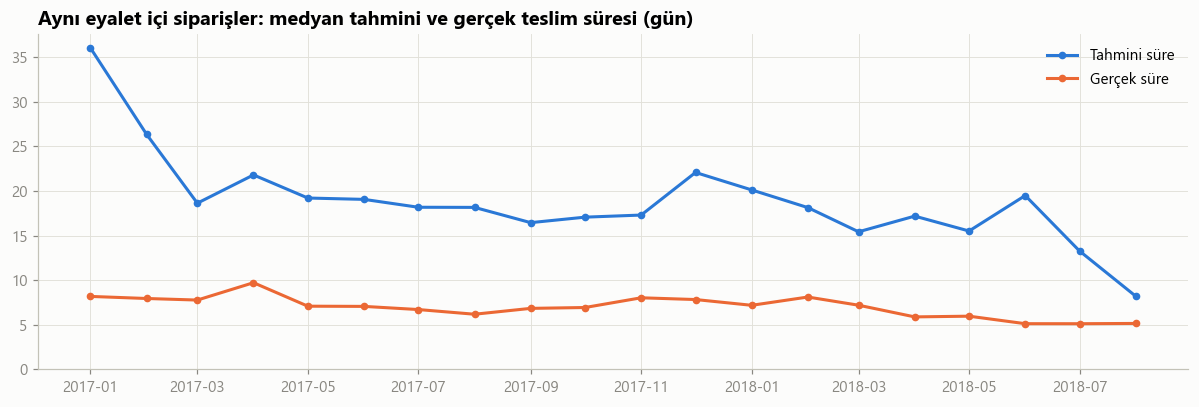

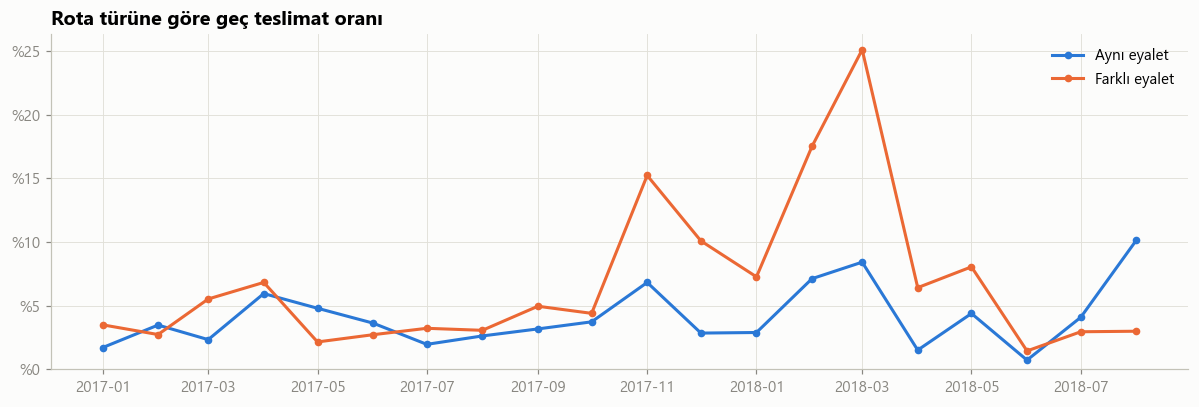

tahmini_medyan               gercek_medyan                \
aynı_eyalet    Aynı eyalet Farklı eyalet   Aynı eyalet Farklı eyalet   
ay                                                                     
2018-04-01           17.18         27.03          5.88         12.26   
2018-05-01           15.51         25.20          5.96         12.44   
2018-06-01           19.49         31.46          5.12          9.84   
2018-07-01           13.26         22.38          5.11          9.02   
2018-08-01            8.20         18.12          5.14          8.35   

               gec_oran                
aynı_eyalet Aynı eyalet Farklı eyalet  
ay                                     
2018-04-01         0.02          0.06  
2018-05-01         0.04          0.08  
2018-06-01         0.01          0.01  
2018-07-01         0.04          0.03  
2018-08-01         0.10          0.03

In [6]:
rota = pd.DataFrame({
    "ay": v["ay"], "aynı_eyalet": X["ayni_eyalet"].map({1: "Aynı eyalet", 0: "Farklı eyalet"}),
    "tahmini": X["tahmini_sure_gun"], "gercek": v["teslim_suresi"], "gec": y})
ozet = rota.groupby(["ay", "aynı_eyalet"]).agg(
    tahmini_medyan=("tahmini", "median"), gercek_medyan=("gercek", "median"), gec_oran=("gec", "mean"))
yerel = ozet.xs("Aynı eyalet", level=1)
uzak = ozet.xs("Farklı eyalet", level=1)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(yerel.index, yerel["tahmini_medyan"], color=MAVI, marker="o", markersize=4, label="Tahmini süre")
ax.plot(yerel.index, yerel["gercek_medyan"], color=TURUNCU, marker="o", markersize=4, label="Gerçek süre")
ax.set_title("Aynı eyalet içi siparişler: medyan tahmini ve gerçek teslim süresi (gün)")
ax.set_ylim(0)
ax.legend(frameon=False)
fig.tight_layout()
kaydet(fig, "ml_03_tahmin_kaymasi")
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(yerel.index, yerel["gec_oran"] * 100, color=MAVI, marker="o", markersize=4, label="Aynı eyalet")
ax.plot(uzak.index, uzak["gec_oran"] * 100, color=TURUNCU, marker="o", markersize=4, label="Farklı eyalet")
ax.set_title("Rota türüne göre geç teslimat oranı")
ax.yaxis.set_major_formatter(YUZDE)
ax.set_ylim(0)
ax.legend(frameon=False)
fig.tight_layout()
kaydet(fig, "ml_03b_rota_gecikme")
plt.show()
ozet.loc["2018-04":].unstack().round(2)

**Ağustos 2018'de Olist, aynı eyalet içindeki siparişlerin tahmini teslim süresini yaklaşık yarıya indirdi** (medyan ~17 günden 8 güne).
Gerçek teslim süresi ise ~5 günde sabit kaldı. Sonuç olarak yakın siparişlerin geç teslimat oranı %2'den **%10**'a fırladı ve ilk kez uzak siparişleri geçti.

Bu, modeller için bir **rejim değişikliği**:
- Gradient boosting, geçmişte öğrendiği "yakın sipariş ve uzun tahmini süre = güvenli" eşiklerine sıkı sıkıya bağlı. Kural değişince ters yönde tahmin üretiyor.
- Lojistik regresyon daha basit, tek yönlü ilişkiler öğrendiği için değişimden daha az etkileniyor.

**Model seçimi:** Lojistik regresyon nihai model olarak seçildi. Hem testte daha yüksek skor aldı hem de koşullar değiştiğinde daha dayanıklı.
*Not:* Bu seçim test dönemi incelenerek yapıldığı için raporlanan test skoru bir miktar iyimser olabilir. Seçim yalnızca iki aday arasında yapıldığından bu iyimserlik sınırlı.

**İş açısından ders:** Tahmini teslim süresini kısaltmak müşteriye cazip görünse de, gerçek teslimat hızlanmadan yapıldığında doğrudan geç teslimata ve düşük puana dönüşüyor.

## 5. Riskli siparişleri işaretlemek ne kadar işe yarar?

**Yakalama eğrisi:** Siparişler modelin risk skoruna göre sıralanıyor. En riskli %X işaretlendiğinde tüm geç siparişlerin ne kadarı yakalanıyor?

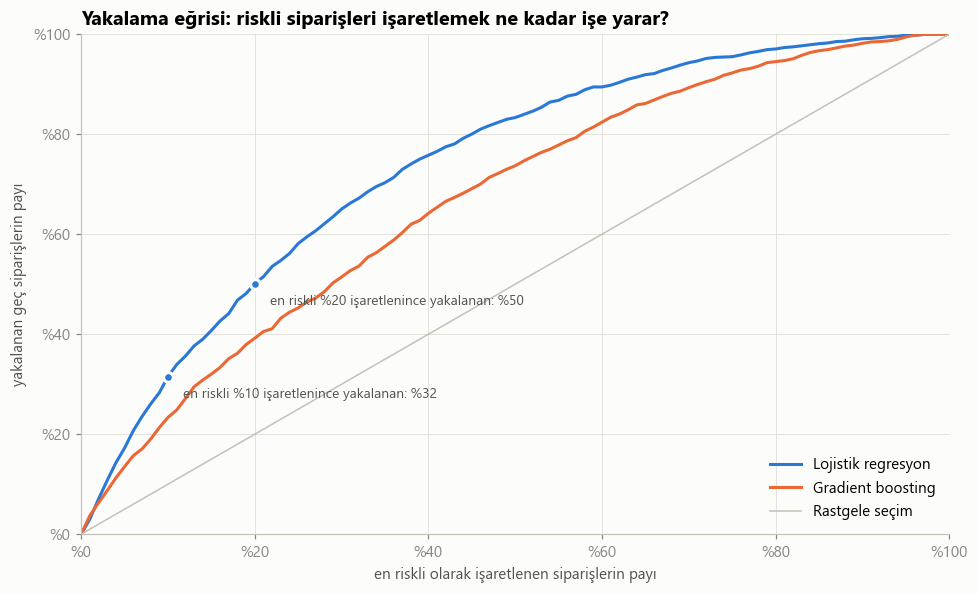

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
oranlar = np.linspace(0, 1, 101)
for ad, renk in [("Lojistik regresyon", MAVI), ("Gradient boosting", TURUNCU)]:
    egri = [yakalama(y_test, tahmin[ad], o) * 100 if o > 0 else 0 for o in oranlar]
    ax.plot(oranlar * 100, egri, color=renk, label=ad)
ax.plot([0, 100], [0, 100], color=ORTA_GRI, linewidth=1, label="Rastgele seçim")
for o in (0.1, 0.2):
    deger = yakalama(y_test, tahmin["Lojistik regresyon"], o) * 100
    ax.scatter([o * 100], [deger], color=MAVI, s=40, zorder=3, edgecolor=ortak.YUZEY, linewidth=2)
    ax.annotate(f"en riskli %{sayi(o * 100)} işaretlenince yakalanan: %{sayi(deger)}", xy=(o * 100, deger),
                xytext=(10, -14), textcoords="offset points", color=YAZI, fontsize=9)
ax.set_title("Yakalama eğrisi: riskli siparişleri işaretlemek ne kadar işe yarar?")
ax.set_xlabel("en riskli olarak işaretlenen siparişlerin payı")
ax.set_ylabel("yakalanan geç siparişlerin payı")
ax.xaxis.set_major_formatter(YUZDE)
ax.yaxis.set_major_formatter(YUZDE)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
kaydet(fig, "ml_04_yakalama")
plt.show()

In [8]:
p = tahmin["Lojistik regresyon"]
satirlar = []
for o in (0.05, 0.10, 0.20, 0.30):
    n = int(len(p) * o)
    secilen = np.asarray(y_test)[np.argsort(-p)[:n]]
    satirlar.append({"işaretlenen pay": f"%{sayi(o * 100)}", "işaretlenen sipariş": n,
                     "işaretlenenlerde geç oranı (%)": secilen.mean() * 100,
                     "yakalanan geç sipariş (%)": secilen.sum() / y_test.sum() * 100,
                     "kaldıraç (lift)": secilen.mean() / y_test.mean()})
pd.DataFrame(satirlar).set_index("işaretlenen pay").round(1)

,işaretlenen sipariş,işaretlenenlerde geç oranı (%),yakalanan geç sipariş (%),kaldıraç (lift)
işaretlenen pay,,,,
%5,1607,15.20,17.20,3.40
%10,3215,13.90,31.50,3.20
%20,6430,11.10,50.10,2.50
%30,9645,9.60,65.00,2.20


## 6. Model neye bakıyor?

**Permütasyon önemi:** Test verisinde bir özelliğin değerleri rastgele karıştırıldığında modelin PR-AUC'si ne kadar düşüyor?
Düşüş ne kadar büyükse, model o özelliğe o kadar dayanıyor.

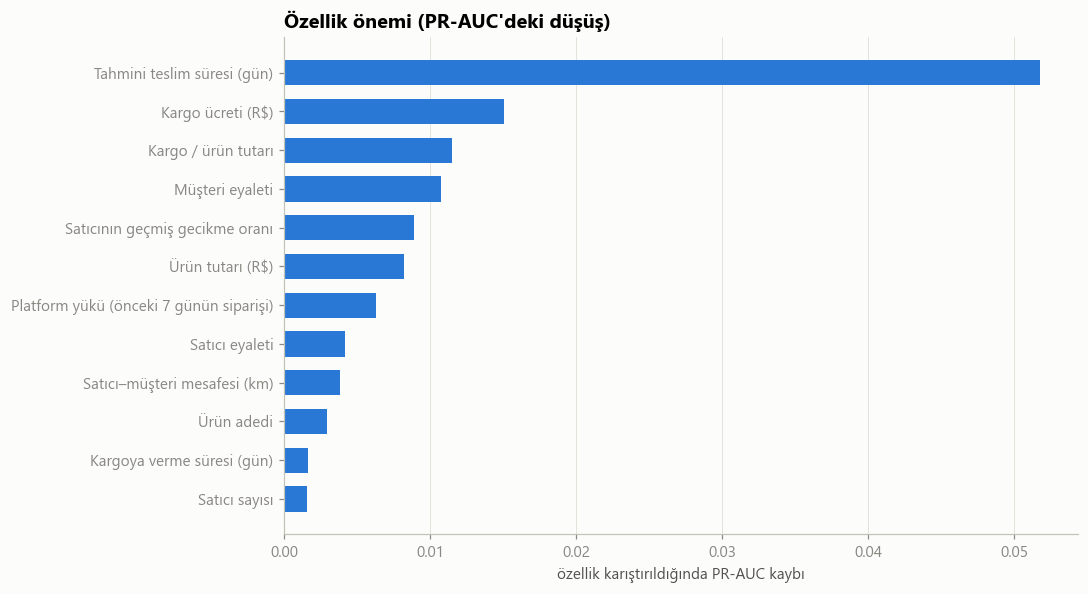

In [9]:
pi = permutation_importance(lojistik, X_test, y_test, scoring="average_precision",
                            n_repeats=5, random_state=42)
onem = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()

ilk = onem.tail(12)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh([AD[c] for c in ilk.index], ilk.values, color=MAVI, height=0.65)
ax.set_title("Özellik önemi (PR-AUC'deki düşüş)")
ax.set_xlabel("özellik karıştırıldığında PR-AUC kaybı")
ax.grid(axis="y", visible=False)
fig.tight_layout()
kaydet(fig, "ml_05_ozellik_onemi")
plt.show()

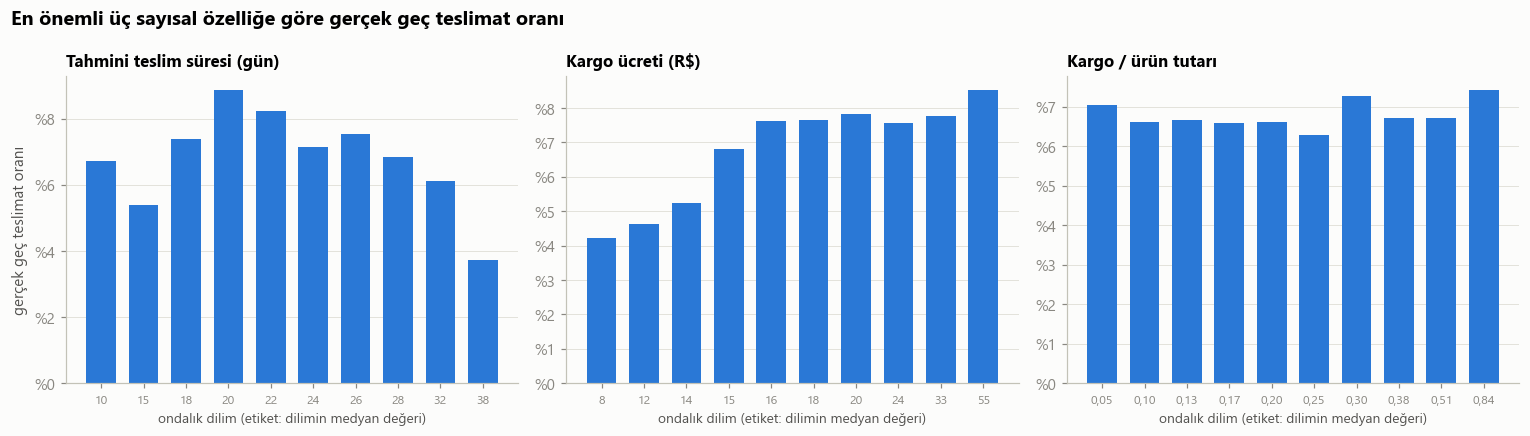

In [10]:
en_onemli = [c for c in onem.index[::-1] if c in sayisal][:3]
fig, eksenler = plt.subplots(1, 3, figsize=(14, 4))
for ax, ozellik in zip(eksenler, en_onemli):
    dilim = pd.qcut(X[ozellik].rank(method="first"), 10, labels=range(1, 11))
    grup = (pd.DataFrame({"x": X[ozellik], "y": y, "d": dilim})
            .groupby("d", observed=True).agg(oran=("y", "mean"), medyan=("x", "median")))
    sira = grup.index.astype(int)
    ax.bar(sira, grup["oran"] * 100, color=MAVI, width=0.7)
    ax.set_xticks(sira, [sayi(m, 2 if m < 1 else 0) for m in grup["medyan"]], fontsize=8)
    ax.set_title(AD[ozellik], fontsize=11)
    ax.yaxis.set_major_formatter(YUZDE)
    ax.set_ylim(0)
    ax.grid(axis="x", visible=False)
    ax.set_xlabel("ondalık dilim (etiket: dilimin medyan değeri)", fontsize=9)
eksenler[0].set_ylabel("gerçek geç teslimat oranı")
fig.suptitle("En önemli üç sayısal özelliğe göre gerçek geç teslimat oranı", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
kaydet(fig, "ml_06_risk_etkenleri")
plt.show()

- **Tahmini teslim süresi:** İlişki doğrusal değil. Gecikme riski orta uzunluktaki tahminlerde (~20 gün) en yüksek. Çok kısa tahminler genellikle yakın siparişlere, çok uzun tahminler ise bol tampon bırakılmış siparişlere ait; ikisinde de risk daha düşük.
- **Kargo ücreti:** Ücret arttıkça risk artıyor. Kargo ücreti mesafe ve hacmin dolaylı bir göstergesi.
- **Kargo / ürün tutarı:** Tek başına zayıf bir etken; risk tüm dilimlerde %6–7,5 arasında kalıyor. Model bu bilgiyi diğer özelliklerle birlikte kullanıyor.

## 7. Sonuç

| # | Bulgu |
|---|---|
| 1 | Seçilen model (lojistik regresyon), test döneminde **ROC-AUC 0,75** aldı. En riskli %10'luk dilim işaretlendiğinde geç siparişlerin **%31,5**'i yakalanıyor; bu, rastgele seçimin **3,2 katı**. En riskli %20'lik dilim, geç siparişlerin yarısını içeriyor. |
| 2 | Modelin en çok dayandığı bilgiler: **tahmini teslim süresi**, **kargo ücreti**, müşteri eyaleti ve satıcının geçmiş gecikme oranı. |
| 3 | Geç teslimatın önemli bir kısmı siparişin kendi özelliklerinden değil, **dönemsel şoklardan** (Black Friday 2017, Şubat–Mart 2018, Mayıs 2018 kamyoncu grevi) kaynaklanıyor. Bu yüzden sipariş anındaki bilgilerle tahmin gücü sınırlı. |
| 4 | Ağustos 2018'de aynı eyalet içi siparişlerin tahmini süresi yaklaşık yarıya indirildi ve bu siparişlerin geç oranı %2'den %10'a çıktı. Daha karmaşık olan gradient boosting modeli bu değişiklikte rastgele tahminin altına düştü. |

**Kullanım önerileri**
- Her gün en riskli %10'luk siparişler lojistik ekibine öncelikli liste olarak iletilebilir. Bu siparişlerde müşteri önceden bilgilendirilebilir.
- Tahmini teslim süresi politikası her değiştiğinde model yeniden eğitilmeli ve aylık ROC-AUC izlenmeli (model izleme).
- Tahmini süreyi kısaltma kararları, gerçek teslim süresi verisiyle birlikte değerlendirilmeli.

**Sınırlılıklar**
- Veri setinde kargo firması, hava durumu veya grev gibi dış etkenlere dair bilgi yok.
- Teslim edilmemiş ve iptal edilen siparişler modele dahil edilmedi.
- Nihai model seçimi test dönemindeki analizden etkilendiği için, raporlanan skorun yeni bir dönemde doğrulanması gerekir.